# Food-11 Dataset — Data Inspection and Cleaning

## Objective

This notebook focuses on inspecting and preparing the Food-11 dataset for the NutriVision project.

The main objectives are:

1. Verify the dataset structure and image counts.
2. Check image integrity and identify corrupted files.
3. Analyze image formats, dimensions, and color modes.
4. Identify potential duplicate images.
5. Analyze the distribution of food categories across the training, validation, and evaluation splits.
6. Document data-quality issues and determine whether any cleaning is necessary.

**Important:** The original images will remain unchanged. Any cleaning decisions will be documented, and the original train/validation/evaluation split assignments will be preserved.

In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import seaborn as sns

# Check the current working directory
cwd = Path.cwd()
print("Current working directory:", cwd)

# Automatically identify the project root
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

# Food-11 dataset location
FOOD11_DIR = PROJECT_ROOT / "data" / "raw" / "food11" / "archive"

# Check that the directory exists
print("Project root:", PROJECT_ROOT)
print("Food-11 directory:", FOOD11_DIR)
print("Dataset exists:", FOOD11_DIR.exists())

# Expected splits
SPLITS = ["training", "validation", "evaluation"]

for split in SPLITS:
    print(f"{split}: {(FOOD11_DIR / split).exists()}")


Matplotlib is building the font cache; this may take a moment.


Current working directory: C:\Users\dell\NutriVision\notebooks
Project root: C:\Users\dell\NutriVision
Food-11 directory: C:\Users\dell\NutriVision\data\raw\food11\archive
Dataset exists: True
training: True
validation: True
evaluation: True


In [3]:

# Store information about valid images
image_records = []

# Store information about corrupted images
corrupted_images = []

# Supported image extensions
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

for split in SPLITS:
    split_dir = FOOD11_DIR / split

    for category_dir in split_dir.iterdir():
        if not category_dir.is_dir():
            continue

        for image_path in category_dir.iterdir():

            if image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            try:
                with Image.open(image_path) as img:
                    img.verify()

                # Reopen image to read its properties
                with Image.open(image_path) as img:
                    image_records.append({
                        "split": split,
                        "category": category_dir.name,
                        "filename": image_path.name,
                        "format": img.format,
                        "width": img.width,
                        "height": img.height,
                        "mode": img.mode,
                        "file_size_kb": round(
                            image_path.stat().st_size / 1024, 2
                        ),
                        "file_path": str(image_path)
                    })

            except (OSError, UnidentifiedImageError, ValueError):
                corrupted_images.append({
                    "split": split,
                    "category": category_dir.name,
                    "filename": image_path.name,
                    "file_path": str(image_path)
                })

# Create DataFrames
image_df = pd.DataFrame(image_records)
corrupted_df = pd.DataFrame(corrupted_images)

# Display results
print("IMAGE INSPECTION RESULTS")
print("-" * 40)
print("Valid images:", len(image_df))
print("Corrupted images:", len(corrupted_df))
print("Total inspected images:", len(image_df) + len(corrupted_df))


IMAGE INSPECTION RESULTS
----------------------------------------
Valid images: 16643
Corrupted images: 0
Total inspected images: 16643


## 2. Image Properties Analysis

In this section, we analyze the technical characteristics of Food-11 images, including their file formats, dimensions, color modes, and file sizes.

This analysis helps us identify inconsistencies in image representation and determine whether additional preprocessing will be necessary in later stages.

In [4]:

# 1. Image formats
print("IMAGE FORMATS")
display(image_df["format"].value_counts())

# 2. Color modes
print("\nIMAGE COLOR MODES")
display(image_df["mode"].value_counts())

# 3. Image dimensions
print("\nIMAGE DIMENSIONS")
display(image_df[["width", "height"]].describe())

# 4. Image file sizes
print("\nIMAGE FILE SIZES (KB)")
display(image_df["file_size_kb"].describe())

# 5. Number of unique dimensions
print("\nNumber of unique image dimensions:")
print(image_df[["width", "height"]].drop_duplicates().shape[0])


IMAGE FORMATS


format
JPEG    16643
Name: count, dtype: int64


IMAGE COLOR MODES


mode
RGB    16643
Name: count, dtype: int64


IMAGE DIMENSIONS


,width,height
count,16643.000000,16643.000000
mean,531.545575,496.012017
std,250.931358,180.382750
min,220.000000,207.000000
25%,512.000000,454.500000
50%,512.000000,512.000000
75%,512.000000,512.000000
max,9542.000000,6144.000000



IMAGE FILE SIZES (KB)


count    16643.000000
mean        69.734290
std        204.312678
min          6.200000
25%         39.320000
50%         48.320000
75%         58.180000
max       9874.500000
Name: file_size_kb, dtype: float64


Number of unique image dimensions:
825


## 3. Investigation of Image Size Outliers

Although all images passed the integrity check, the dataset contains considerable variation in image dimensions and file sizes.

In this section, we investigate the largest images to determine whether they represent unusual data entries that require additional preprocessing.

In [5]:

# Calculate total pixels and aspect ratio
image_df["total_pixels"] = image_df["width"] * image_df["height"]

image_df["aspect_ratio"] = (
    image_df["width"] / image_df["height"]
)

# 10 images with the largest dimensions
print("TOP 10 IMAGES BY RESOLUTION")

display(
    image_df.nlargest(10, "total_pixels")[
        ["split", "category", "filename",
         "width", "height", "total_pixels", "file_size_kb"]
    ]
)

# 10 largest files
print("\nTOP 10 IMAGES BY FILE SIZE")

display(
    image_df.nlargest(10, "file_size_kb")[
        ["split", "category", "filename",
         "width", "height", "file_size_kb"]
    ]
)


TOP 10 IMAGES BY RESOLUTION


,split,category,filename,width,height,total_pixels,file_size_kb
13276,validation,Vegetable-Fruit,81.jpg,9216,6144,56623104,9624.68
16547,evaluation,Vegetable-Fruit,22.jpg,9542,5126,48912292,2048.27
9542,training,Vegetable-Fruit,445.jpg,7360,4912,36152320,6819.53
9779,training,Vegetable-Fruit,659.jpg,5616,3744,21026304,9874.50
13810,evaluation,Dairy product,98.jpg,5616,3744,21026304,9261.81
16436,evaluation,Vegetable-Fruit,12.jpg,5488,3584,19668992,1468.80
16455,evaluation,Vegetable-Fruit,137.jpg,5488,3584,19668992,1468.80
16425,evaluation,Vegetable-Fruit,11.jpg,5250,3500,18375000,4681.75
13080,validation,Vegetable-Fruit,112.jpg,5184,3456,17915904,3806.05
13227,validation,Vegetable-Fruit,37.jpg,4848,3496,16948608,198.15



TOP 10 IMAGES BY FILE SIZE


,split,category,filename,width,height,file_size_kb
9779,training,Vegetable-Fruit,659.jpg,5616,3744,9874.50
13276,validation,Vegetable-Fruit,81.jpg,9216,6144,9624.68
13810,evaluation,Dairy product,98.jpg,5616,3744,9261.81
9542,training,Vegetable-Fruit,445.jpg,7360,4912,6819.53
9259,training,Vegetable-Fruit,190.jpg,3264,2448,5412.47
16425,evaluation,Vegetable-Fruit,11.jpg,5250,3500,4681.75
13186,validation,Vegetable-Fruit,208.jpg,4384,3435,4578.81
9332,training,Vegetable-Fruit,256.jpg,3072,2304,4219.00
13087,validation,Vegetable-Fruit,119.jpg,3221,2638,4119.77
13086,validation,Vegetable-Fruit,118.jpg,5000,3000,4017.45


## 4. Duplicate Image Detection

In this section, we identify duplicate images using SHA-256 cryptographic hashes.

This allows us to detect identical image files even when they have different filenames.

We will check for duplicates within individual splits and across different splits to identify potential data leakage.

No images will be deleted during this analysis.

In [6]:

import hashlib

def calculate_sha256(file_path):
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(8192), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


# Calculate hash for every image
image_df["sha256"] = image_df["file_path"].apply(
    calculate_sha256
)

# Find duplicated hashes
duplicate_mask = image_df.duplicated(
    subset=["sha256"],
    keep=False
)

duplicates_df = image_df[duplicate_mask].sort_values(
    by="sha256"
)

print("DUPLICATE IMAGE ANALYSIS")
print("-" * 40)

print("Total images:", len(image_df))
print("Unique image hashes:", image_df["sha256"].nunique())
print("Images belonging to duplicate groups:", len(duplicates_df))
print(
    "Number of duplicate groups:",
    duplicates_df["sha256"].nunique()
)

# Display duplicates if found
if len(duplicates_df) > 0:
    display(
        duplicates_df[
            ["split", "category", "filename", "sha256"]
        ]
    )
else:
    print("No exact duplicate images found.")


DUPLICATE IMAGE ANALYSIS
----------------------------------------
Total images: 16643
Unique image hashes: 16020
Images belonging to duplicate groups: 1245
Number of duplicate groups: 622


,split,category,filename,sha256
13494,evaluation,Bread,277.jpg,0010a118a2f6b08e33fc93a5587abe2c8042ae3cc984fd...
10048,validation,Bread,262.jpg,0010a118a2f6b08e33fc93a5587abe2c8042ae3cc984fd...
11202,validation,Fried food,100.jpg,00804ac83a26354092961a37441c9fb69e732ef8a88514...
14875,evaluation,Fried food,46.jpg,00804ac83a26354092961a37441c9fb69e732ef8a88514...
16121,evaluation,Soup,287.jpg,01c9d50078be5c8d920463d28129ee78fb12d1a7b4c541...
...,...,...,...,...
7021,training,Seafood,296.jpg,fef336aacf4787c0745beb56c5a47deb05a685ffafeb12...
2827,training,Dessert,912.jpg,ff4416cb4a535cbaeb1185dba16c8804868d196eb89c49...
10825,validation,Dessert,57.jpg,ff4416cb4a535cbaeb1185dba16c8804868d196eb89c49...
10522,validation,Dessert,233.jpg,ffff0d5058b19bc5faddbabf817299beaf5461f2f7c237...


## 5. Detailed Duplicate Analysis

After detecting exact duplicate images, we investigate their distribution across dataset splits and food categories.

The purpose is to identify potential data leakage between training, validation, and evaluation, as well as possible inconsistencies in food-category labels.

Duplicate images will not be removed until this analysis is complete.

In [8]:

# Group duplicate images by their SHA-256 hash
duplicate_groups = (
    duplicates_df.groupby("sha256")
    .agg(
        number_of_copies=("sha256", "size"),
        number_of_splits=("split", "nunique"),
        number_of_categories=("category", "nunique"),
        splits=("split", lambda x: ", ".join(sorted(set(x)))),
        categories=("category", lambda x: ", ".join(sorted(set(x)))),
        filenames=("filename", lambda x: ", ".join(x))
    )
    .reset_index()
)

# 1. Duplicates appearing across different splits
cross_split_duplicates = duplicate_groups[
    duplicate_groups["number_of_splits"] > 1
]

# 2. Duplicates appearing under different categories
cross_category_duplicates = duplicate_groups[
    duplicate_groups["number_of_categories"] > 1
]

# 3. Duplicates appearing within only one split
within_split_duplicates = duplicate_groups[
    duplicate_groups["number_of_splits"] == 1
]

print("DETAILED DUPLICATE ANALYSIS")
print("-" * 45)

print("Total duplicate groups:", len(duplicate_groups))

print(
    "Groups appearing across multiple splits:",
    len(cross_split_duplicates)
)

print(
    "Groups appearing under multiple categories:",
    len(cross_category_duplicates)
)

print(
    "Groups appearing within only one split:",
    len(within_split_duplicates)
)

print("\nDUPLICATE GROUPS BY SPLIT COMBINATION")

display(
    cross_split_duplicates["splits"].value_counts()
)

print("\nDUPLICATE GROUPS WITH DIFFERENT CATEGORIES")

display(
    cross_category_duplicates[
        ["number_of_copies", "splits", "categories", "filenames"]
    ].head(20)
)


DETAILED DUPLICATE ANALYSIS
---------------------------------------------
Total duplicate groups: 622
Groups appearing across multiple splits: 611
Groups appearing under multiple categories: 0
Groups appearing within only one split: 11

DUPLICATE GROUPS BY SPLIT COMBINATION


splits
evaluation, validation    311
evaluation, training      249
training, validation       51
Name: count, dtype: int64


DUPLICATE GROUPS WITH DIFFERENT CATEGORIES


,number_of_copies,splits,categories,filenames


## 6. Evaluating the Impact of Deduplication

Before modifying the dataset, we simulate the removal of exact duplicate images.

We prioritize retaining images in the training split, followed by validation and evaluation. This helps prevent the same image from appearing across multiple splits.

The simulation allows us to measure the impact on dataset size without modifying the original files.

In [9]:

# Define split priority
split_priority = {
    "training": 0,
    "validation": 1,
    "evaluation": 2
}

# Work on a copy of the image inventory
deduplication_df = image_df.copy()

deduplication_df["split_priority"] = (
    deduplication_df["split"].map(split_priority)
)

# Sort so that the preferred copy comes first
deduplication_df = deduplication_df.sort_values(
    by=["sha256", "split_priority", "file_path"]
)

# Keep one copy of each exact image
deduplication_df["keep"] = ~deduplication_df.duplicated(
    subset=["sha256"],
    keep="first"
)

# Compare original and simulated counts
original_counts = (
    image_df.groupby("split").size()
    .rename("original_images")
)

retained_counts = (
    deduplication_df[deduplication_df["keep"]]
    .groupby("split").size()
    .rename("retained_images")
)

summary_df = pd.concat(
    [original_counts, retained_counts],
    axis=1
).fillna(0).astype(int)

summary_df["removed_images"] = (
    summary_df["original_images"] -
    summary_df["retained_images"]
)

summary_df["retained_percentage"] = (
    summary_df["retained_images"] /
    summary_df["original_images"] * 100
).round(2)

print("SIMULATED DEDUPLICATION RESULTS")
display(summary_df)

print("\nTOTAL ORIGINAL IMAGES:", len(image_df))
print("TOTAL UNIQUE IMAGES:", image_df["sha256"].nunique())
print(
    "TOTAL IMAGES THAT WOULD BE REMOVED:",
    (~deduplication_df["keep"]).sum()
)


SIMULATED DEDUPLICATION RESULTS


,original_images,retained_images,removed_images,retained_percentage
split,,,,
evaluation,3347,2783,564,83.15
training,9866,9861,5,99.95
validation,3430,3376,54,98.43



TOTAL ORIGINAL IMAGES: 16643
TOTAL UNIQUE IMAGES: 16020
TOTAL IMAGES THAT WOULD BE REMOVED: 623


## 7. Class Distribution After Deduplication

In this section, we compare the original class distribution with the simulated deduplicated dataset.

The objective is to determine whether duplicate removal disproportionately affects specific food categories and whether all categories retain sufficient images across the three splits.

,split,category,original_images,retained_images,removed_images,retained_percentage
0,evaluation,Bread,368,268,100,72.83
1,evaluation,Dairy product,148,148,0,100.00
2,evaluation,Dessert,500,440,60,88.00
3,evaluation,Egg,335,330,5,98.51
4,evaluation,Fried food,287,221,66,77.00
5,evaluation,Meat,432,323,109,74.77
6,evaluation,Noodles-Pasta,147,147,0,100.00
7,evaluation,Rice,96,96,0,100.00
8,evaluation,Seafood,303,203,100,67.00
9,evaluation,Soup,500,384,116,76.80


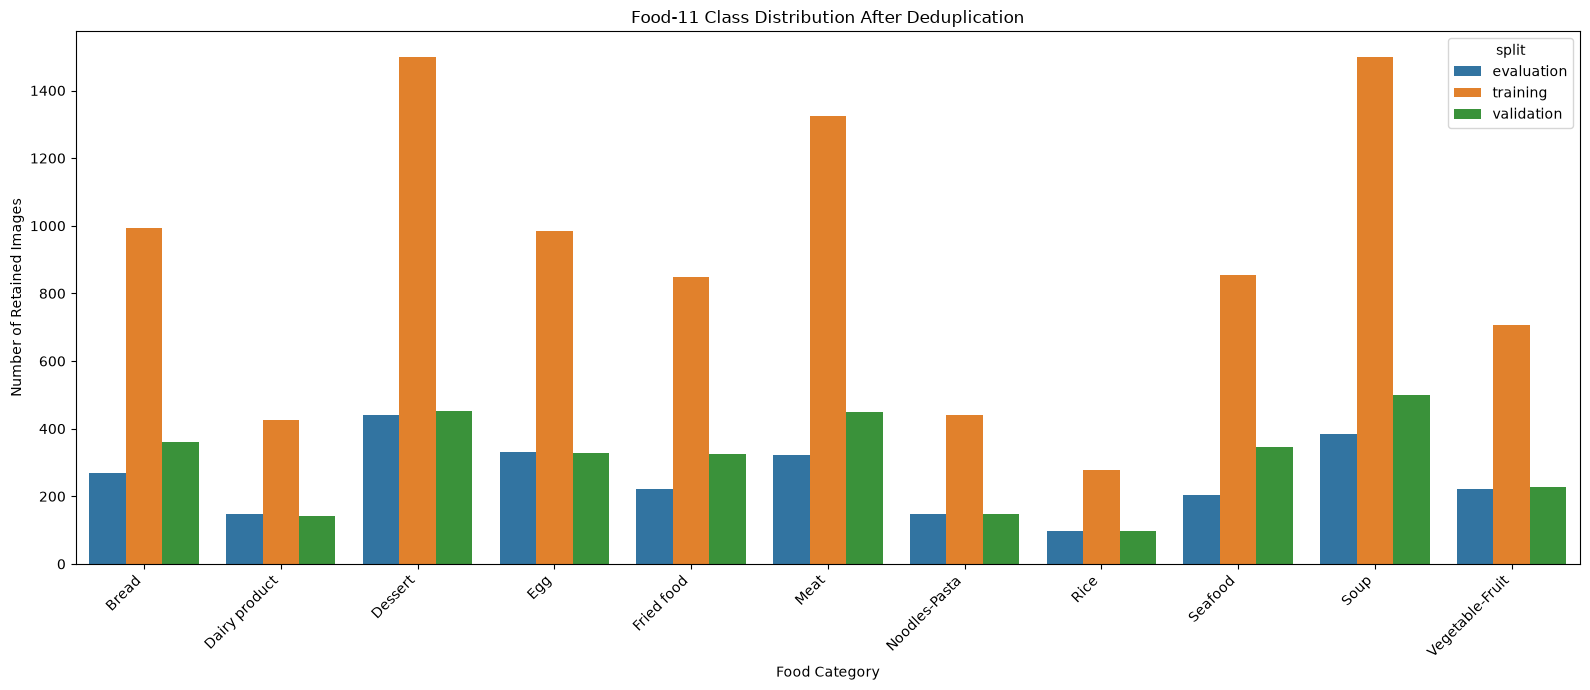

In [10]:

# Original category distribution
original_class_counts = (
    image_df.groupby(["split", "category"])
    .size()
    .rename("original_images")
)

# Retained category distribution after deduplication
retained_class_counts = (
    deduplication_df[deduplication_df["keep"]]
    .groupby(["split", "category"])
    .size()
    .rename("retained_images")
)

# Combine both tables
class_comparison = pd.concat(
    [original_class_counts, retained_class_counts],
    axis=1
).fillna(0).astype(int)

class_comparison["removed_images"] = (
    class_comparison["original_images"] -
    class_comparison["retained_images"]
)

class_comparison["retained_percentage"] = (
    class_comparison["retained_images"] /
    class_comparison["original_images"] * 100
).round(2)

display(class_comparison.reset_index())

# Visual comparison
plot_df = class_comparison.reset_index()

plt.figure(figsize=(16, 7))

sns.barplot(
    data=plot_df,
    x="category",
    y="retained_images",
    hue="split"
)

plt.title("Food-11 Class Distribution After Deduplication")
plt.xlabel("Food Category")
plt.ylabel("Number of Retained Images")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 8. Global Deduplication and Dataset Splitting

Since the original Food-11 dataset contains exact duplicate images across its original splits, we decided to create new dataset partitions.

First, we retain only one copy of each unique image using its SHA-256 hash. Since no duplicate groups were found with conflicting category labels, the original category labels can be preserved.

Next, we create new stratified partitions using the following proportions:

- Training: 60%
- Validation: 20%
- Evaluation: 20%

Stratification ensures that the distribution of food categories remains approximately consistent across the three splits.

A fixed random seed is used to ensure reproducibility.

In [11]:

from sklearn.model_selection import train_test_split

# 1. Keep only one copy of each unique image
unique_df = deduplication_df[
    deduplication_df["keep"]
].copy()

# Remove temporary columns
unique_df = unique_df.drop(
    columns=["keep", "split_priority"]
)

print("Unique images:", len(unique_df))
print("Unique hashes:", unique_df["sha256"].nunique())

# 2. First split: 60% training, 40% temporary
train_df, temp_df = train_test_split(
    unique_df,
    test_size=0.40,
    stratify=unique_df["category"],
    random_state=42
)

# 3. Second split: 20% validation, 20% evaluation
val_df, eval_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["category"],
    random_state=42
)

# 4. Assign new split names
train_df = train_df.copy()
val_df = val_df.copy()
eval_df = eval_df.copy()

train_df["new_split"] = "training"
val_df["new_split"] = "validation"
eval_df["new_split"] = "evaluation"

# 5. Combine all partitions
food11_clean_df = pd.concat(
    [train_df, val_df, eval_df],
    ignore_index=True
)

# 6. Display results
print("\nNEW DATASET SPLITS")
print("-" * 40)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Evaluation:", len(eval_df))
print("Total:", len(food11_clean_df))

print(
    "\nUnique image hashes:",
    food11_clean_df["sha256"].nunique()
)

print(
    "Duplicate hashes:",
    food11_clean_df["sha256"].duplicated().sum()
)

print("\nCATEGORY DISTRIBUTION")

display(
    food11_clean_df.groupby(
        ["new_split", "category"]
    ).size().unstack(fill_value=0)
)


Unique images: 16020
Unique hashes: 16020

NEW DATASET SPLITS
----------------------------------------
Training: 9612
Validation: 3204
Evaluation: 3204
Total: 16020

Unique image hashes: 16020
Duplicate hashes: 0

CATEGORY DISTRIBUTION


category,Bread,Dairy product,Dessert,Egg,Fried food,Meat,Noodles-Pasta,Rice,Seafood,Soup,Vegetable-Fruit
new_split,,,,,,,,,,,
evaluation,325,143,478,328,279,420,147,94,281,477,232
training,974,430,1435,986,837,1258,440,283,843,1430,696
validation,325,144,478,329,279,419,146,94,281,477,232


## 9. Final Dataset Validation and Export

The final dataset is validated to ensure that:

- No exact duplicate images remain.
- No duplicate image is shared between different splits.
- All 11 food categories are represented in every split.
- The 60/20/20 partition proportions are respected.

After validation, the dataset manifest is exported as a CSV file in the processed data directory.

The original Food-11 images remain unchanged in the raw data directory.

In [12]:

# 1. Verify that hashes do not overlap between splits

train_hashes = set(train_df["sha256"])
val_hashes = set(val_df["sha256"])
eval_hashes = set(eval_df["sha256"])

print("FINAL DUPLICATE VERIFICATION")
print("-" * 40)

print("Training / Validation overlap:", len(train_hashes & val_hashes))
print("Training / Evaluation overlap:", len(train_hashes & eval_hashes))
print("Validation / Evaluation overlap:", len(val_hashes & eval_hashes))

# 2. Verify that every category exists in every split

expected_categories = set(unique_df["category"].unique())

for split_name, split_df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Evaluation", eval_df)
]:
    actual_categories = set(split_df["category"].unique())

    print(
        f"{split_name} has all categories:",
        actual_categories == expected_categories
    )

# 3. Create processed output directory

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "food11"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 4. Save the cleaned dataset manifest

food11_clean_df.to_csv(
    OUTPUT_DIR / "food11_clean_manifest.csv",
    index=False
)

# 5. Save split summary

split_summary = (
    food11_clean_df.groupby("new_split")
    .size()
    .reset_index(name="image_count")
)

split_summary.to_csv(
    OUTPUT_DIR / "food11_split_summary.csv",
    index=False
)

print("\nFILES SAVED SUCCESSFULLY")
print("Output directory:", OUTPUT_DIR)
print("Manifest:", OUTPUT_DIR / "food11_clean_manifest.csv")
print("Split summary:", OUTPUT_DIR / "food11_split_summary.csv")


FINAL DUPLICATE VERIFICATION
----------------------------------------
Training / Validation overlap: 0
Training / Evaluation overlap: 0
Validation / Evaluation overlap: 0
Training has all categories: True
Validation has all categories: True
Evaluation has all categories: True

FILES SAVED SUCCESSFULLY
Output directory: C:\Users\dell\NutriVision\data\processed\food11
Manifest: C:\Users\dell\NutriVision\data\processed\food11\food11_clean_manifest.csv
Split summary: C:\Users\dell\NutriVision\data\processed\food11\food11_split_summary.csv


# Food-11 Dataset — Data Preparation and Cleaning Report

## 1. Dataset Overview

For the NutriVision project, we selected the Food-11 dataset, which contains food images belonging to 11 different categories.

The original dataset contains three predefined partitions:

- Training
- Validation
- Evaluation

The dataset contains 16,643 JPEG images organized into 11 food categories.

Our objective was to inspect the images, identify data-quality problems, remove exact duplicates, and create new dataset partitions suitable for subsequent development.

## 2. Image Integrity Inspection

We inspected all images using Python and the Pillow library.

For every image, we checked whether it could be opened and whether its file structure was valid.

Results:

| Metric | Result |
|---|---:|
| Total inspected images | 16,643 |
| Valid images | 16,643 |
| Corrupted images | 0 |

All images passed the integrity check. Therefore, no images needed to be removed because of corruption.

## 3. Image Properties Analysis

We analyzed the image formats, color modes, dimensions, and file sizes.

### 3.1 Image formats

All 16,643 images use the JPEG format.

### 3.2 Color modes

All 16,643 images use RGB color mode.

Therefore, no format or color-mode conversion was necessary during this preparation stage.

### 3.3 Image dimensions

| Statistic | Width | Height |
|---|---:|---:|
| Minimum | 220 | 207 |
| Mean | 531.55 | 496.01 |
| Median | 512 | 512 |
| Maximum | 9,542 | 6,144 |

We identified 825 unique image dimensions.

This indicates that images do not all have identical resolutions. Most images are approximately 512 × 512 pixels, although some have significantly higher resolutions.

### 3.4 File sizes

| Statistic | Result |
|---|---:|
| Mean file size | 69.73 KB |
| Median file size | 48.32 KB |
| Maximum file size | 9,874.5 KB |

Some images have unusually large file sizes and resolutions.

However, these images passed the integrity checks, so we retained them. Image resizing can be performed later when preparing model inputs.

## 4. Duplicate Image Detection

We used SHA-256 cryptographic hashing to identify exact duplicate images.

The results revealed:

| Metric | Result |
|---|---:|
| Total images | 16,643 |
| Unique image hashes | 16,020 |
| Duplicate groups | 622 |
| Images belonging to duplicate groups | 1,245 |
| Extra copies beyond unique images | 623 |

### 4.1 Duplicate distribution

We investigated where duplicate images appeared.

| Duplicate pattern | Groups |
|---|---:|
| Evaluation and Validation | 311 |
| Evaluation and Training | 249 |
| Training and Validation | 51 |
| Within a single split | 11 |

We also checked whether duplicate images were assigned to different food categories.

No duplicate groups with conflicting category labels were found.

### 4.2 Data leakage

The presence of identical images across the original training, validation, and evaluation partitions creates a potential data leakage problem.

For example, an image could appear in both training and evaluation, meaning that the evaluation would not be completely independent.

Therefore, we decided to create new partitions after removing exact duplicates.

## 5. Global Deduplication

We simulated a deduplication strategy and found that prioritizing the original training split would disproportionately reduce the evaluation dataset.

Instead, we decided to:

1. Consider all 16,643 images together.
2. Group images using their SHA-256 hashes.
3. Retain only one copy of each unique image.
4. Preserve the original food-category labels.

This resulted in a dataset containing:

**16,020 unique images across 11 categories.**

The original images were not modified or deleted.

## 6. Creating New Dataset Partitions

After global deduplication, we created new stratified partitions using Scikit-learn's `train_test_split`.

The selected proportions were:

- Training: 60